# Mini Project: Clustering Before and After PCA
**Dataset:** Date Fruit Dataset (898 dates, 34 numerical features, 7 types)

**Goal:** See how PCA affects K-Means clustering results.

Group members: Shaden, Norah, Aljoharh, Sulaiman.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [4]:
URL = "https://raw.githubusercontent.com/DataRohit/Date-Fruit-Classification/master/Date_Fruit_Datasets.xlsx"
df = pd.read_excel(URL)

names = {"DOKOL": "Sukkari", "SAFAVI": "Safawi", "ROTANA": "Ruthana", "DEGLET": "Deglet",
         "SOGAY": "Sagai", "IRAQI": "Barni", "BERHI": "Barhi"}
df["Variety"] = df["Class"].map(names)
df.head()

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class,Variety
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI,Barhi
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI,Barhi
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI,Barhi
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI,Barhi
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI,Barhi


In [5]:
df.shape

(898, 36)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 898 entries, 0 to 897
Data columns (total 36 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   AREA           898 non-null    int64  
 1   PERIMETER      898 non-null    float64
 2   MAJOR_AXIS     898 non-null    float64
 3   MINOR_AXIS     898 non-null    float64
 4   ECCENTRICITY   898 non-null    float64
 5   EQDIASQ        898 non-null    float64
 6   SOLIDITY       898 non-null    float64
 7   CONVEX_AREA    898 non-null    int64  
 8   EXTENT         898 non-null    float64
 9   ASPECT_RATIO   898 non-null    float64
 10  ROUNDNESS      898 non-null    float64
 11  COMPACTNESS    898 non-null    float64
 12  SHAPEFACTOR_1  898 non-null    float64
 13  SHAPEFACTOR_2  898 non-null    float64
 14  SHAPEFACTOR_3  898 non-null    float64
 15  SHAPEFACTOR_4  898 non-null    float64
 16  MeanRR         898 non-null    float64
 17  MeanRG         898 non-null    float64
 18  MeanRB    

In [7]:
#number of dates in each type
df["Class"].value_counts()

,count
Class,
DOKOL,204
SAFAVI,199
ROTANA,166
DEGLET,98
SOGAY,94
IRAQI,72
BERHI,65


## Preprocessing

In [9]:
df.isnull().sum()

,0
AREA,0
PERIMETER,0
MAJOR_AXIS,0
MINOR_AXIS,0
ECCENTRICITY,0
EQDIASQ,0
SOLIDITY,0
CONVEX_AREA,0
EXTENT,0
ASPECT_RATIO,0


In [12]:
pd.crosstab(df['Class'], df['Variety'])

Variety,Barhi,Barni,Deglet,Ruthana,Safawi,Sagai,Sukkari
Class,,,,,,,
BERHI,65,0,0,0,0,0,0
DEGLET,0,0,98,0,0,0,0
DOKOL,0,0,0,0,0,0,204
IRAQI,0,72,0,0,0,0,0
ROTANA,0,0,0,166,0,0,0
SAFAVI,0,0,0,0,199,0,0
SOGAY,0,0,0,0,0,94,0


In [15]:
X = df.drop(["Class", "Variety"], axis=1)
y = df["Class"]

standardization (required because features have very different ranges, e.g. AREA is in the hundreds of thousands):

In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Choose the number of clusters (K)

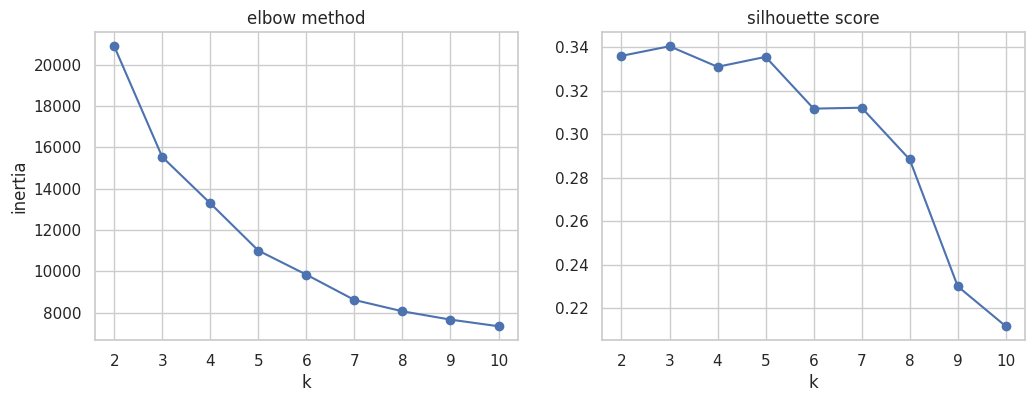

In [18]:
inertia = []
sil = []
k_values = range(2, 11)

for k in k_values:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(X_scaled)
  inertia.append(kmeans.inertia_)
  sil.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_values, inertia, marker="o")
ax[0].set_title("elbow method")
ax[0].set_xlabel("k")
ax[0].set_ylabel("inertia")
ax[1].plot(k_values, sil, marker='o')
ax[1].set_title("silhouette score")
ax[1].set_xlabel("k")
plt.show()

The Silhouette score is highest around K = 3, and there is no clear elbow.
But the dataset has 7 real date types, so we use **K = 7** to be able to compare the clusters with the real types.

In [19]:
k = 7

## K-Means before PCA (all 34 features)

In [20]:
kmeans_b = KMeans(n_clusters=k, random_state=42, n_init=10)
labels_b = kmeans_b.fit_predict(X_scaled)

sil_b = silhouette_score(X_scaled, labels_b)
ari_b = adjusted_rand_score(y, labels_b)
print("silhouette:", sil_b)
print("ARI:", ari_b)

silhouette: 0.31220624201526276
ARI: 0.750480672324549


## Apply PCA (2 components)

In [21]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [22]:
print("variance explained by each component:", pca.explained_variance_ratio_.round(3))
print("total variance kept:", round(sum(pca.explained_variance_ratio_), 3))

variance explained by each component: [0.41  0.229]
total variance kept: 0.639


## K-Means after PCA (2 components)

In [24]:
kmeans_a = KMeans(n_clusters=k, random_state=42, n_init=10)
labels_a = kmeans_a.fit_predict(X_pca)

sil_a = silhouette_score(X_pca, labels_a)
ari_a = adjusted_rand_score(y, labels_a)
print("silhouette:", sil_a)
print("ARI:", ari_a)

silhouette: 0.4100815442145617
ARI: 0.5618209900532111


## Visualization

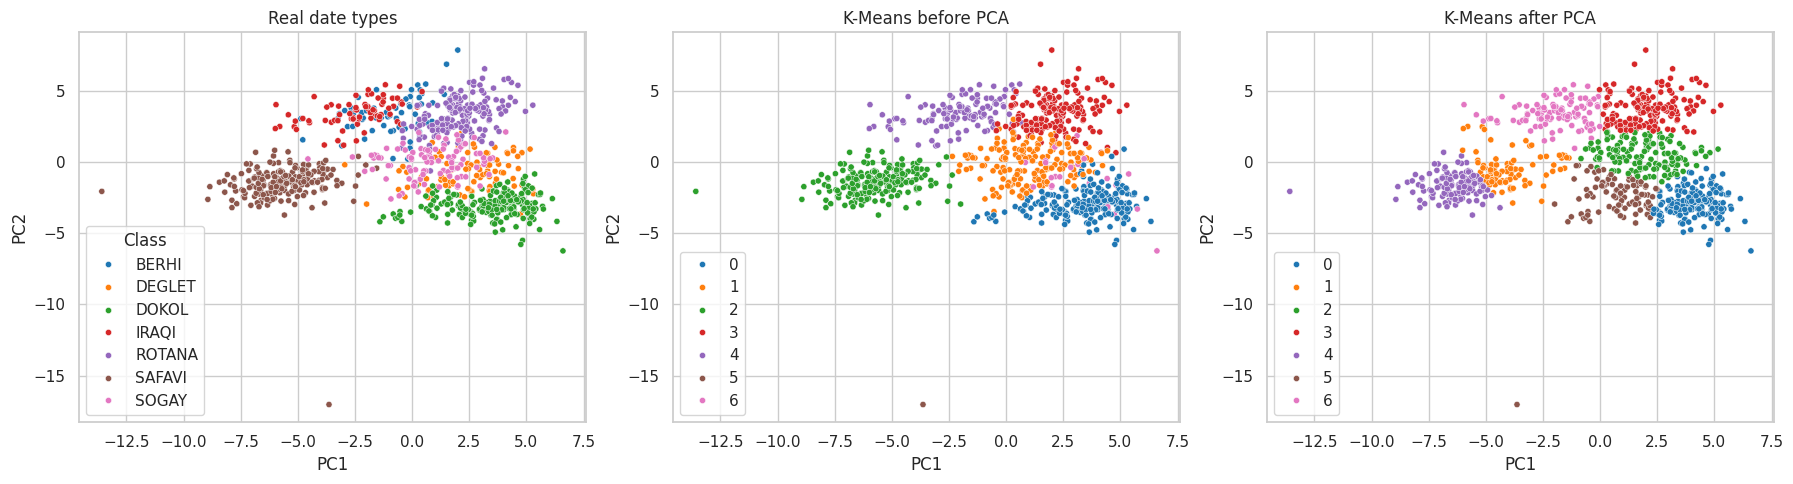

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='tab10', s=20, ax=ax[0])
ax[0].set_title('Real date types')

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_b, palette='tab10', s=20, ax=ax[1])
ax[1].set_title('K-Means before PCA')

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_a, palette='tab10', s=20, ax=ax[2])
ax[2].set_title('K-Means after PCA')

for a in ax:
    a.set_xlabel('PC1')
    a.set_ylabel('PC2')

plt.tight_layout()
plt.show()

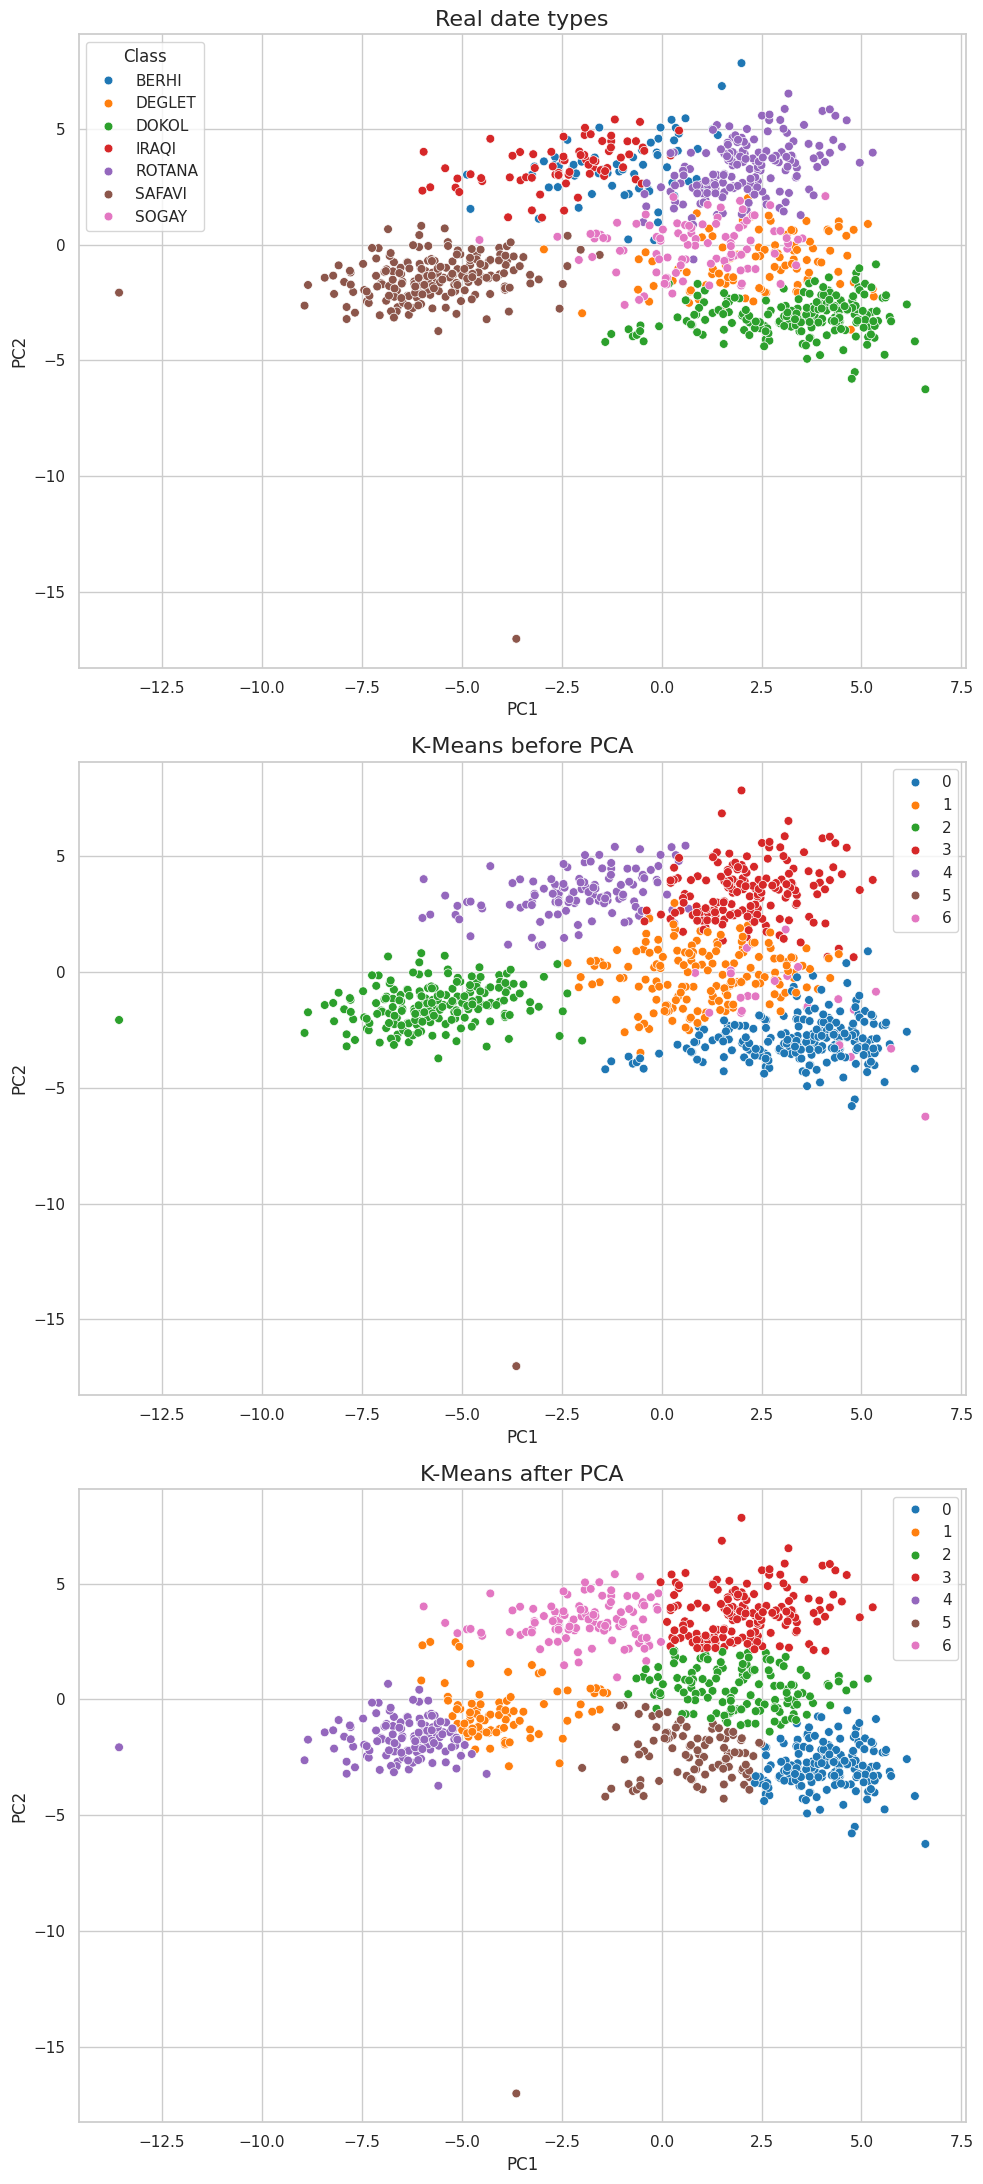

In [28]:
fig, ax = plt.subplots(3, 1, figsize=(10, 22))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='tab10', s=40, ax=ax[0])
ax[0].set_title('Real date types', fontsize=16)

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_b, palette='tab10', s=40, ax=ax[1])
ax[1].set_title('K-Means before PCA', fontsize=16)

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_a, palette='tab10', s=40, ax=ax[2])
ax[2].set_title('K-Means after PCA', fontsize=16)

for a in ax:
    a.set_xlabel('PC1')
    a.set_ylabel('PC2')

plt.tight_layout()
plt.show()

## Comparison

In [29]:
results = pd.DataFrame({
    "approach" : ["before PCA", "after PCA"],
    "silhouette" : [sil_b, sil_a],
    "ARI" : [ari_b, ari_a]
})
results.round(3)

,approach,silhouette,ARI
0,before PCA,0.312,0.750
1,after PCA,0.410,0.562


- **Silhouette:** how well separated the clusters are (higher = better).
- **ARI:** how close the clusters are to the real date types (1 = perfect match).

## 10. Analysis

**How did PCA affect clustering results?**
- Silhouette went **up** from 0.31 to 0.41 → clusters look more separated after PCA.
- ARI went **down** from 0.75 to 0.56 → clusters match the real date types less after PCA.
- So the clusters look cleaner in 2D, but they are less correct.

**Did visualization become clearer?**
Yes. With 34 features we can't plot the data directly. With 2 components we can see the clusters in one plot.
- **SAFAVI** and **DOKOL** are clearly separated from the other types.
- **DEGLET**, **SOGAY** and **BERHI** overlap a lot in the middle of the plot, so they are hard to separate in 2D.
- After PCA, K-Means split **SAFAVI** into 2 clusters, which is one reason ARI dropped.
- There is one outlier date at the bottom of the plot (PC2 ≈ -17).

**Did we lose important information?**
Yes. The 2 components kept only **64%** of the variance, so about **36%** was lost.
The drop in ARI (0.75 → 0.56) shows that some of the lost information was important for separating the date types.

**Which approach is better and why?**
- **Before PCA** is better for accuracy (higher ARI), because it uses all the information.
- **PCA with 2 components** is better for visualization only.
- From the bonus, **3 components** is a good middle: it keeps 75% of the variance and ARI goes back up to 0.69.

## Bonus: different number of PCA components

In [30]:
n_list = [2, 3, 5, 10, 15, 20]
rows = []

for n in n_list:
    X_n = PCA(n_components=n).fit_transform(X_scaled)
    labels_n = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_n)
    variance = PCA(n_components=n).fit(X_scaled).explained_variance_ratio_.sum()
    rows.append([n, variance, silhouette_score(X_n, labels_n), adjusted_rand_score(y, labels_n)])

bonus = pd.DataFrame(rows, columns=['Components', 'Variance kept', 'Silhouette', 'ARI'])
bonus.round(3)

,Components,Variance kept,Silhouette,ARI
0,2,0.639,0.410,0.562
1,3,0.753,0.417,0.691
2,5,0.865,0.408,0.691
3,10,0.970,0.336,0.687
4,15,0.992,0.321,0.688
5,20,0.999,0.317,0.687


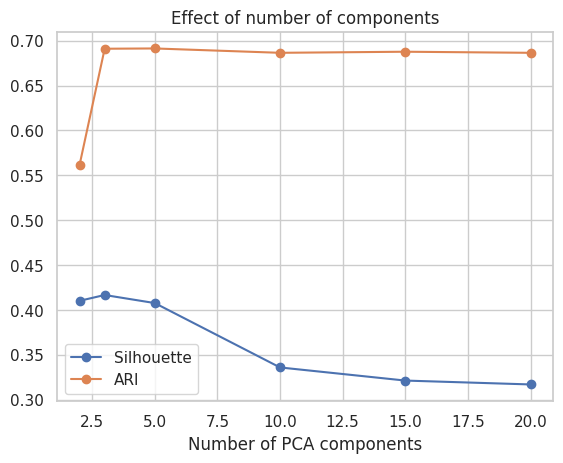

In [31]:
plt.plot(bonus['Components'], bonus['Silhouette'], marker='o', label='Silhouette')
plt.plot(bonus['Components'], bonus['ARI'], marker='o', label='ARI')
plt.xlabel('Number of PCA components')
plt.legend()
plt.title('Effect of number of components')
plt.show()

##Bonus: DBSCAN after PCA

I tried a few `eps` values (0.3 to 0.8). `eps=0.5` with `min_samples=10` gave the best balance between number of clusters and noise.

In [32]:
dbscan = DBSCAN(eps=0.5, min_samples=10)
labels_db = dbscan.fit_predict(X_pca)

print('Number of clusters:', len(set(labels_db)) - (1 if -1 in labels_db else 0))
print('Noise points:', list(labels_db).count(-1))
print('ARI:', round(adjusted_rand_score(y, labels_db), 3))

Number of clusters: 8
Noise points: 253
ARI: 0.403


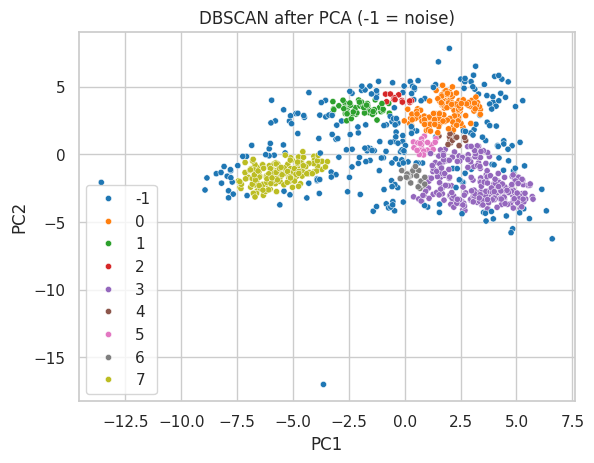

In [33]:
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_db, palette='tab10', s=20)
plt.title('DBSCAN after PCA (-1 = noise)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

## 13. Key Insights

1. Standardization was necessary because the features have very different ranges.
2. A higher Silhouette after PCA does not mean better clustering: ARI dropped from 0.75 to 0.56.
3. 2 PCA components kept only 64% of the variance, which was not enough for 7 date types.
4. 3 components is a good trade-off (75% variance, ARI 0.69). Adding more components after that didn't improve ARI.
5. DBSCAN did not work well here: it marked many points as noise (253 out of 898) and had a lower ARI (0.40) than K-Means.
6. Best overall: **K-Means on the full scaled data**. PCA (2D) is mainly useful for visualization.